In [35]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import requests



# 1. Load both datasets
df_ursf = pd.read_excel('/Users/majdshamashan/Downloads/urssaf_test.xlsx')
df_plants = pd.read_excel('../../03_data_raw/exploration_inputs/plants_with_departments.xlsx')

# 2. Clean the 'City' column in the small dataset 
# (e.g., turns "Sausheim, Mulhouse" into just "Sausheim")
df_plants['Commune_Clean'] = df_plants['City'].str.split(', ').str[0]

# 3. Filter to get only the rows where there is a valid employment number given
df_plants_valid = df_plants.dropna(subset=['employees']).copy()

# 4. Prepare a list to store the final matched rows
results = []

# 5. Loop through each specific plant to find it in the URSSAF dataset
for index, row in df_plants_valid.iterrows():
    commune = row['Commune_Clean']
    plant_emp = row['employees']
    year = int(row['year'])
    
    # Check the year: URSSAF data only goes up to 2024.
    # If the plant year is 2025 or higher, we use 2024 as the closest match.
    ursf_year = 2025 if year > 2025 else year
    year_col = f"Effectifs salariés {ursf_year}"
    
    # Filter URSSAF dataset to find exact matches for this specific commune
    match_ursf = df_ursf[df_ursf['Nom commune'] == commune]
    
    if not match_ursf.empty:
        # Sum the employment numbers from the URSSAF dataset for the corresponding year
        ursf_emp_sum = match_ursf[year_col].sum()
        
        results.append({
            'Commune': commune,
            'Year_Reported': year,
            'Plant_Employees': plant_emp,
            'URSSAF_Total': ursf_emp_sum,
            'URSSAF_Year_Used': ursf_year
        })
    else:
        # If no match is found (e.g. spelling difference), set URSSAF Total to 0
        results.append({
            'Commune': commune,
            'Year_Reported': year,
            'Plant_Employees': plant_emp,
            'URSSAF_Total': 0,
            'URSSAF_Year_Used': ursf_year
        })

# 6. Convert the results back into a clean Dataframe and display it!
df_results = pd.DataFrame(results)

# Optional: You can export this directly to a CSV if you want to keep the matched data
#df_results.to_csv('../../03_data_raw/exploration_inputs/plants_with_departments.xlsx', index=False)

print(df_results.to_string(index=False))

              Commune  Year_Reported  Plant_Employees  URSSAF_Total  URSSAF_Year_Used
              Batilly           2025           1938.0        2000.0              2025
                Cléon           2025           3124.0        3170.0              2025
               Dieppe           2025            380.0         380.0              2025
                Douai           2025           4265.0        4220.0              2025
              Le Mans           2024           2000.0        2080.0              2024
             Maubeuge           2025           1835.0        1913.0              2025
              Meyzieu           2025            106.0          99.0              2025
                Ruitz           2025            331.0         823.0              2025
          Sandouville           2025           1865.0        2053.0              2025
                Flins           2023           1941.0        2147.0              2023
Saint André de l'Eure           2025            360.0 

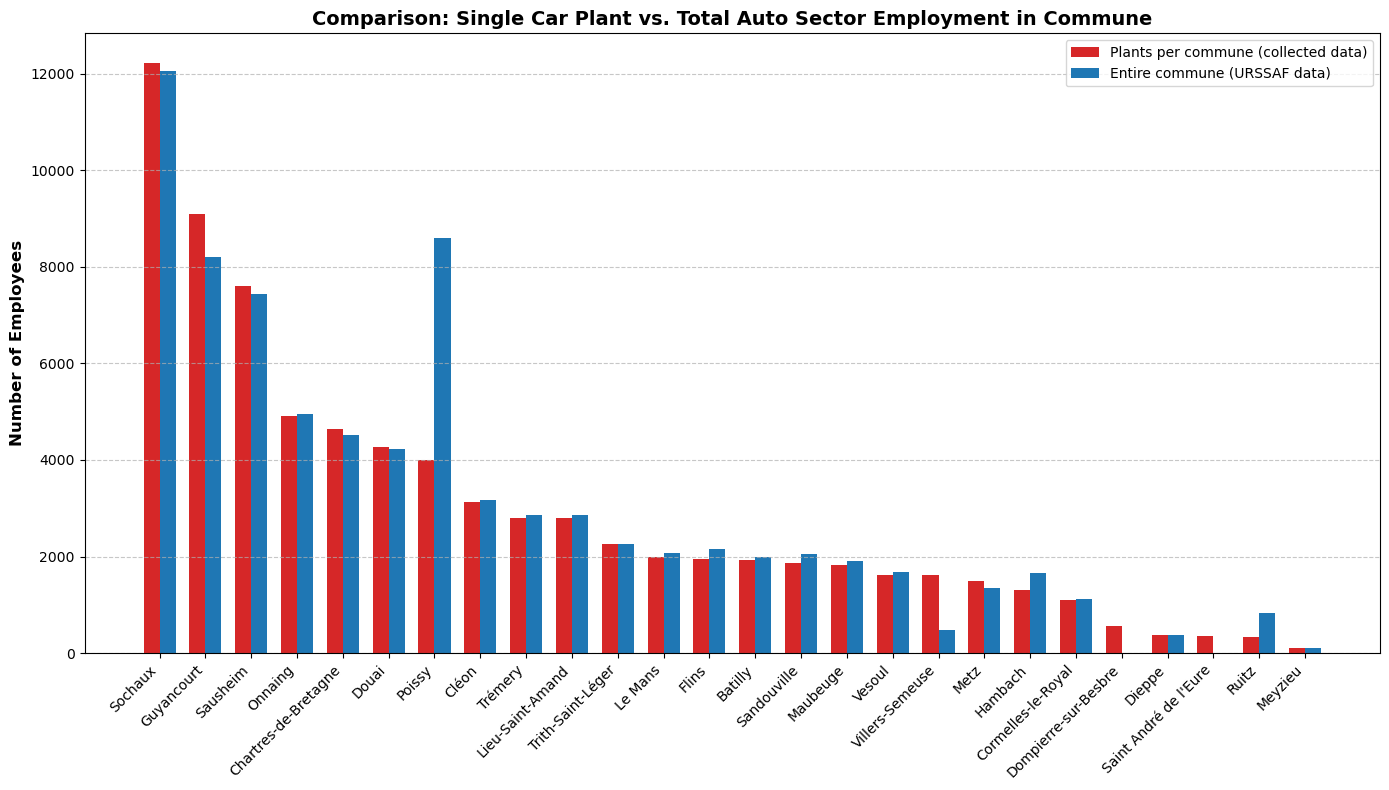

In [36]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the dataset
# df_results = pd.read_csv("matched_plant_urssaf_employment.csv")

# =====================================================================
# 2. THE FIX: Sort by Plant_Employees in descending order
# =====================================================================
df_results = df_results.sort_values(by='Plant_Employees', ascending=False).reset_index(drop=True)

# 3. Set up the figure size
fig, ax = plt.subplots(figsize=(14, 8))

# 4. Define bar width and the x-axis positions for each city
x = np.arange(len(df_results['Commune']))
width = 0.35

# 5. Plot the two sets of bars side-by-side
ax.bar(x - width/2, df_results['Plant_Employees'], width, label='Plants per commune (collected data)', color='tab:red')
ax.bar(x + width/2, df_results['URSSAF_Total'], width, label='Entire commune (URSSAF data)', color='tab:blue')

# 6. Add labels, title, and custom tick marks
ax.set_ylabel('Number of Employees', fontweight='bold', fontsize=12)
ax.set_title('Comparison: Single Car Plant vs. Total Auto Sector Employment in Commune', fontweight='bold', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(df_results['Commune'], rotation=45, ha='right', fontsize=10)
ax.legend()

# 7. Add a subtle grid to the background
ax.grid(axis='y', linestyle='--', alpha=0.7)

# 8. Adjust layout and display!
fig.tight_layout()
plt.show()

In [31]:
import pandas as pd

# Code commune -> value as it appears in LAST
GEO_TO_LAST = {
    "Nom commune": {
        "08105": "Villers-Semeuse",
        "59008": "Douai", "59028": "Douai", "59165": "Douai", "59234": "Douai",
        "59569": "Douai", "59574": "Douai", "59654": "Douai",
        "71263": "Louhans",
        "78029": "Flins", "78238": "Flins",
        "95218": "Éragny",
    },
    "Commune": {
        "71263": "71263 Louhans",
        "95218": "95218 Éragny",
    },
    "EPCI": {
        "12156": "Communauté de communes Aubrac, Carladez et Viadène",
        "12223": "Communauté de communes Aubrac, Carladez et Viadène",
        "15012": "Communauté d'agglomération du Bassin d'Aurillac",
        "15140": "Communauté d'agglomération du Bassin d'Aurillac",
        "15267": "Communauté d'agglomération du Bassin d'Aurillac",
        "54137": "Grand Longwy Agglomération",
        "54575": "Grand Longwy Agglomération",
        "57221": "Communauté d'agglomération du Val de Fensch",
        "57287": "Communauté d'agglomération Portes de France-Thionville",
        "57672": "Communauté d'agglomération Portes de France-Thionville",
        "72375": "Communauté de communes du Pays de l'Huisne Sarthoise",
    },
    "Code EPCI": {
        "57221": 245701222,
        "57287": 245701362,
        "57672": 245701362,
    },
}

df = pd.read_excel(
    "/Users/majdshamashan/Downloads/etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last-test.xlsx",
    dtype={"Code commune": str, "Code département": str},
)

key = df["Code commune"].str.zfill(5)
for col, mapping in GEO_TO_LAST.items():
    new = key.map(mapping)
    df.loc[new.notna(), col] = new[new.notna()]


df.to_excel('/Users/majdshamashan/Downloads/urssaf_test.xlsx', index=False)